<a href="https://colab.research.google.com/github/ihsann2410010447/projek-statistika-Akbar-Ihsan-Nugraha/blob/main/Milestone1_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 1 — Exploratory Data Analysis

**Nama:** Akbar Ihsan Nugraha

**NIM:** 2410010447  
**Dataset:** StudentsPerformance.csv (sumber: Kaggle)

**Isi notebook:**
1. Load Dataset
2. Missing & Duplicate Check
3. Central Tendency
4. Dispersion
5. Visualisasi Univariate
6. Visualisasi Bivariate
7. Insight

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## Step 1 — Load Dataset
Ganti `URL` dengan link **raw** CSV dataset Anda (mis. `raw.githubusercontent.com/...`).

In [11]:
# Membaca file dataset langsung dari penyimpanan lokal Colab
path_dataset = "/content/StudentsPerformance.csv"
df_my = pd.read_csv(path_dataset)

print(f"Shape: {df_my.shape}")
display(df_my.head())
df_my.info()

Shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


## Step 2 — Missing & Duplicate Check

In [12]:
missing = df_my.isnull().sum()
print("=== Missing Values ===")
print(pd.DataFrame({
    'missing': missing,
    'persen (%)': (missing / len(df_my) * 100).round(2)
}))
print(f"\nDuplicates: {df_my.duplicated().sum()}")

=== Missing Values ===
                             missing  persen (%)
gender                             0         0.0
race/ethnicity                     0         0.0
parental level of education        0         0.0
lunch                              0         0.0
test preparation course            0         0.0
math score                         0         0.0
reading score                      0         0.0
writing score                      0         0.0

Duplicates: 0


## Step 3 — Central Tendency

In [13]:
numeric = df_my.select_dtypes(include='number').columns.tolist()
print("Kolom numerik:", numeric)

print("\n=== describe() ===")
display(df_my[numeric].describe().T)

central = pd.DataFrame({
    'mean': df_my[numeric].mean(),
    'median': df_my[numeric].median(),
    'mode': df_my[numeric].mode().iloc[0],
})
print("\n=== Mean / Median / Mode ===")
display(central)

Kolom numerik: ['math score', 'reading score', 'writing score']

=== describe() ===


,count,mean,std,min,25%,50%,75%,max
math score,1000.0,66.089,15.163080,0.0,57.00,66.0,77.0,100.0
reading score,1000.0,69.169,14.600192,17.0,59.00,70.0,79.0,100.0
writing score,1000.0,68.054,15.195657,10.0,57.75,69.0,79.0,100.0



=== Mean / Median / Mode ===


,mean,median,mode
math score,66.089,66.0,65
reading score,69.169,70.0,72
writing score,68.054,69.0,74


## Step 4 — Dispersion

In [14]:
disp = pd.DataFrame({
    'std': df_my[numeric].std(),
    'variance': df_my[numeric].var(),
    'range': df_my[numeric].max() - df_my[numeric].min(),
    'IQR': df_my[numeric].quantile(0.75) - df_my[numeric].quantile(0.25),
    'CV (%)': df_my[numeric].std() / df_my[numeric].mean() * 100,
})
display(disp.round(3))

,std,variance,range,IQR,CV (%)
math score,15.163,229.919,100,20.00,22.943
reading score,14.600,213.166,83,20.00,21.108
writing score,15.196,230.908,90,21.25,22.329


## Step 5 — Visualisasi Univariate
Minimal 3 histogram/boxplot. Ganti `cols_uni` dengan kolom pilihan Anda.

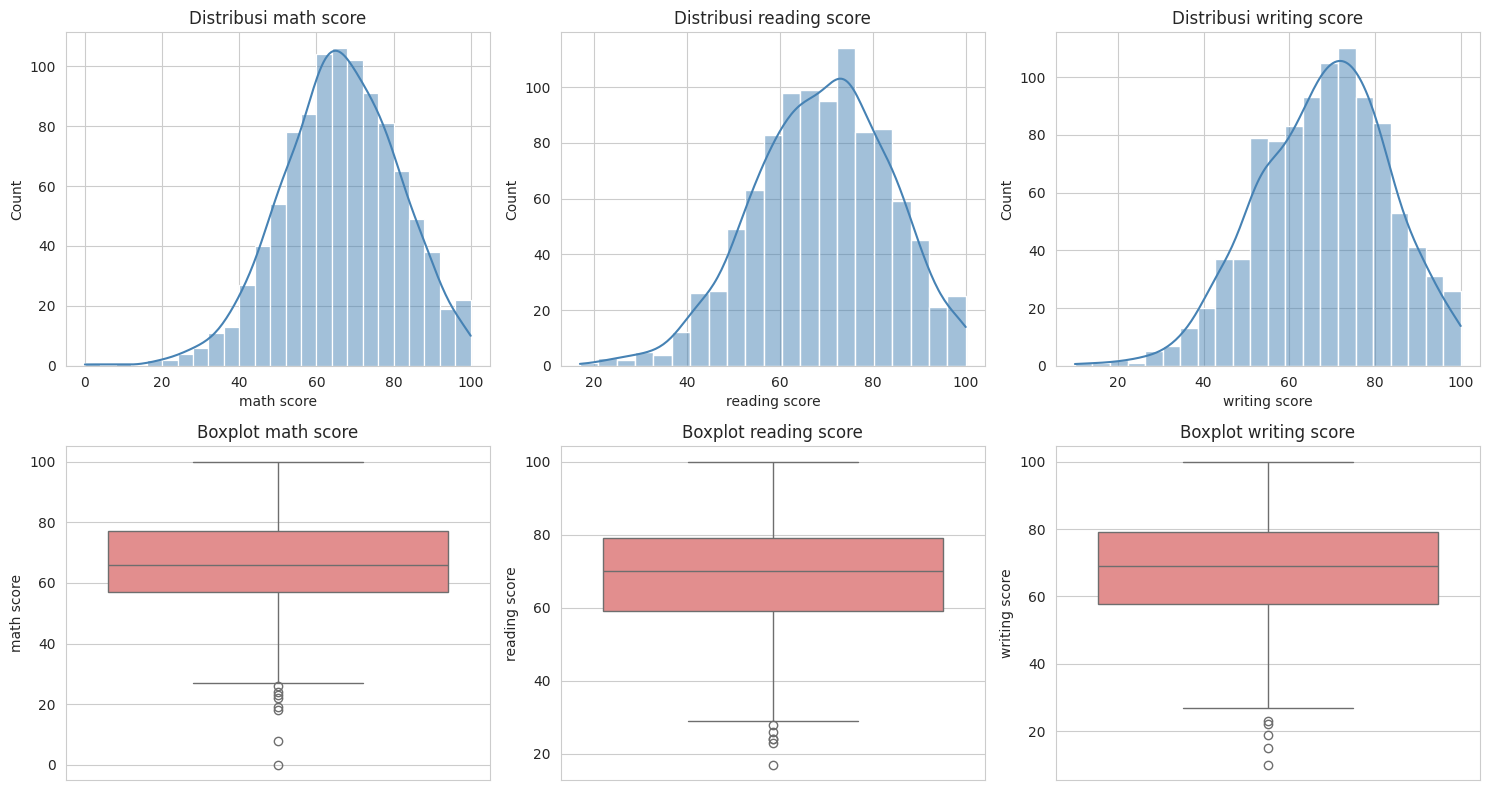

Skewness:
math score      -0.279
reading score   -0.259
writing score   -0.289
dtype: float64


In [15]:
cols_uni = numeric[:3]   # <-- GANTI dengan minimal 3 kolom pilihan Anda

fig, axes = plt.subplots(2, len(cols_uni), figsize=(5 * len(cols_uni), 8), squeeze=False)
for i, c in enumerate(cols_uni):
    sns.histplot(df_my[c], kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'Distribusi {c}')
    sns.boxplot(y=df_my[c], ax=axes[1, i], color='lightcoral')
    axes[1, i].set_title(f'Boxplot {c}')
plt.tight_layout()
plt.show()

# Skewness untuk membantu interpretasi
print("Skewness:")
print(df_my[cols_uni].skew().round(3))

## Step 6 — Visualisasi Bivariate
Minimal scatter plot + heatmap korelasi.

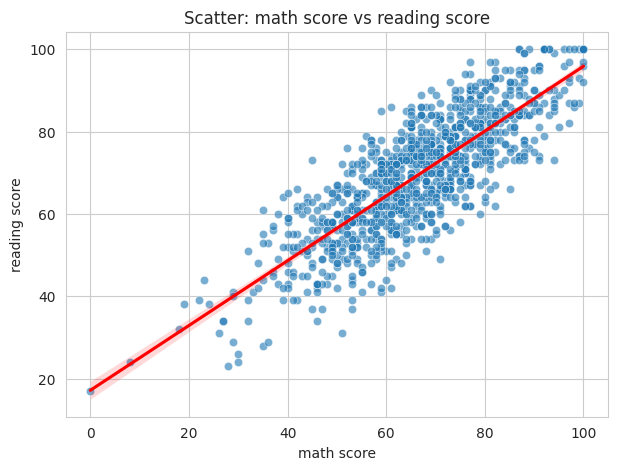

Korelasi math score vs reading score: 0.818


In [16]:
x_col, y_col = numeric[0], numeric[1]   # <-- GANTI dengan pasangan kolom pilihan Anda

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_my, x=x_col, y=y_col, alpha=0.6)
sns.regplot(data=df_my, x=x_col, y=y_col, scatter=False, color='red')
plt.title(f'Scatter: {x_col} vs {y_col}')
plt.show()

print(f"Korelasi {x_col} vs {y_col}: {df_my[x_col].corr(df_my[y_col]):.3f}")

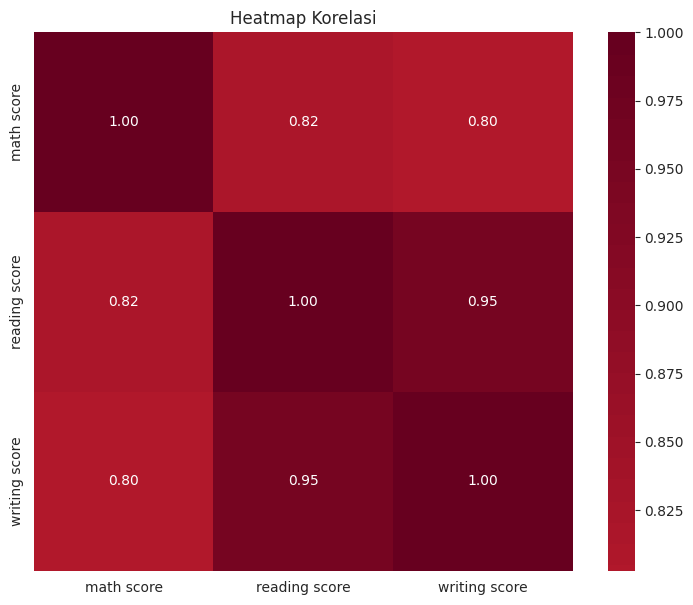

In [17]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_my[numeric].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, square=True)
plt.title('Heatmap Korelasi')
plt.show()

## Step 7 — Insight

1. **Insight 1 (distribusi):** Variabel `math score`, `reading score`, dan `writing score` semuanya berdistribusi cenderung simetris namun sedikit condong ke kiri / *negative skew* (skewness masing-masing sebesar `-0.279`, `-0.259`, dan `-0.289`). Untuk `math score`, median (`66.0`) sangat dekat dengan mean (`66.089`), yang menandakan distribusi nilai siswa cukup merata di sekitar nilai tengah.
2. **Insight 2 (outlier/dispersi):** Ketiga variabel nilai memiliki sebaran yang mirip dengan Koefisien Variasi (CV) berkisar antara `21.1%` hingga `22.9%`. Berdasarkan visualisasi boxplot, terdapat beberapa *outlier* di sisi bawah (nilai sangat rendah), yang menunjukkan adanya sebagian kecil siswa yang mendapatkan nilai jauh di bawah rata-rata kelas.
3. **Insight 3 (korelasi):** Nilai matematika (`math score`) dan nilai membaca (`reading score`) memiliki korelasi positif yang sangat kuat (r = `0.818`), yang berarti siswa yang memiliki kemampuan membaca yang baik cenderung memiliki kemampuan matematika yang baik pula.
4. **Insight 4 (data quality):** Kualitas data sangat baik karena terdapat `0%` missing value pada seluruh kolom dan tidak ditemukan adanya data duplikat (`0` duplikat) di dalam dataset ini.